In [26]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../../code')
sys.path.append('../../code/pycharm')
sys.path.append('../../code/butools2/Python')

from butools.ph import *
from butools.map import *
from butools.queues import *
import time
from butools.mam import *
from butools.dph import *
from scipy.linalg import expm, sinm, cosm

from numpy.linalg import matrix_power
from scipy.stats import rv_discrete
# import seaborn as sns
import random
from scipy.stats import loguniform
from butools.fitting import *
from scipy.special import factorial

from sample_PH import *
from utils import *

from single_station_PH import *

<div dir="rtl">

    
# למה בכלל יש תורים?
    
## במיוחד במערכות יציבות שקצב שירות מקצב הגעה ולכן הנצילות של השרת קטנה מ-100%
    
## התשובה היא שאנשים לא יודעים מתי להגיע.
    
## בואו נעשה את המשחק המחשבתי הבא: נניח ביום ראשון הסופרלנד נפתח. כל אחד רושם בדיוק באיזו שעה הוא עלה לכל מתקן. כמובן שהיו תורים כמו בכל יום. ביום שני כל מי שהגיע ביום ורק הם מגיעים שוב לסופרלנד. כל אחד עולה על כל המתקנים בדיוק ביום הקודם ובדיוק באותן שעות. כל אחד מגיע שנייה לפני שהוא צריך להגיע למתקן. אם כולם יצייתו לחוק הזה אזי שלא יהיו תורים בכלל. 

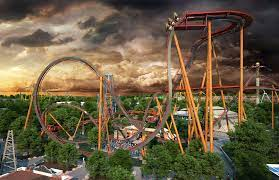

In [27]:
Image('../../Images/sixflags.jpg', width=620)

<div dir="rtl"> 

# מתי יהיו תורים ארוכים? כאשר יש שונות גדולה בזמני הגעה או בזמני שירות
  
<div dir="rtl">

    
##  מה זה אומר שונות גדולה בכלל? 
    
## למשל: תארו לעצמם את הדבר הבא. יש לקוחות שמגיעים להופעה. יש שני סוגים של לקוחות. חלק כבר קנו כרטיסים מראש ורק באים לאסוף. משהו שלוקח 20 שניות. ויש כאלו שרק עכשיו קונים. הם צריכים לבחור איפה יישבו בהופעה ואז לשלם. דבר כזה לוקח 10 דקות. עכשיו תארו שהגעתם להופעה רק לאסוף כרטיסים ויש רק שלושה אנשים לפניכם בתור. הבעיה היא שאף אחד מהם לא קנה כרטיס. תחכו המון זמן. במקרה כזה, יהיו תורים ארוכים למרות שייתכן הרבה רגעים שהשרת פנוי לחלוטין!


<div dir="rtl">

### השונות היא תוצאה של התפלגות זמן השירות או זמנים בין הגעות.
    
#### נראה כל מיני התפלגויות ואת השונות שלהן 
    
### התפלגות מעריכית

### $$ f_X(x)  = \lambda e^{-\lambda x} $$

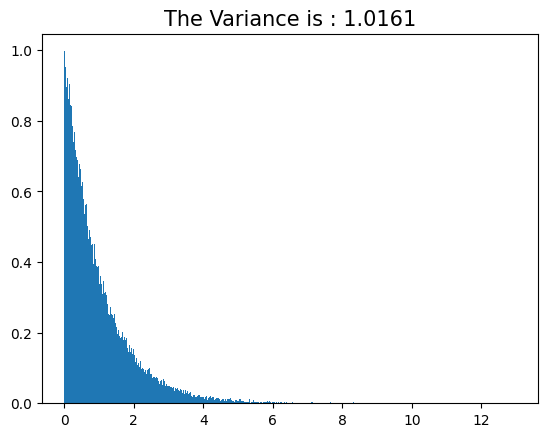

In [28]:
exp_sample = np.random.exponential(1, 50000)
plt.figure()
plt.hist(exp_sample, density = True, bins = 500)
plt.title('The Variance is : '+ str((exp_sample.std())**2)[:6], fontsize= 15)
plt.show()

<div dir="rtl">
    
    
## התפלגות Erlang: סכום של מעריכים.

### סכום של n מעריכיים עם פרטמר $\mu$ יסומן כך: 

$$ X \sim Eralng(n, \mu) $$

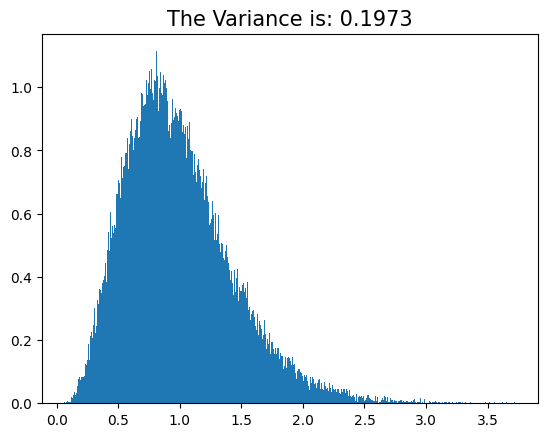

In [29]:
shape, scale = 5, 0.2  # mean=4, std=2*sqrt(2)
eralng_sample = np.random.gamma(shape, scale, 50000)

plt.figure()
plt.hist(eralng_sample, density = True, bins = 500)
plt.title('The Variance is: '+ str((eralng_sample.std())**2)[:6], fontsize= 15)
plt.show()



## Phase type distribution: (PH)
    
<div dir="rtl">
 
# התפלגות PH היא התפלגות שיכולה להציג כל התפלגות רציפה שיש. ניתן כמה דוגמאות:


The Variance is: 0.0086
The Variance is: 1.5094
The Variance is: 0.8354
The Variance is: 0.8443
The Variance is: 0.6650


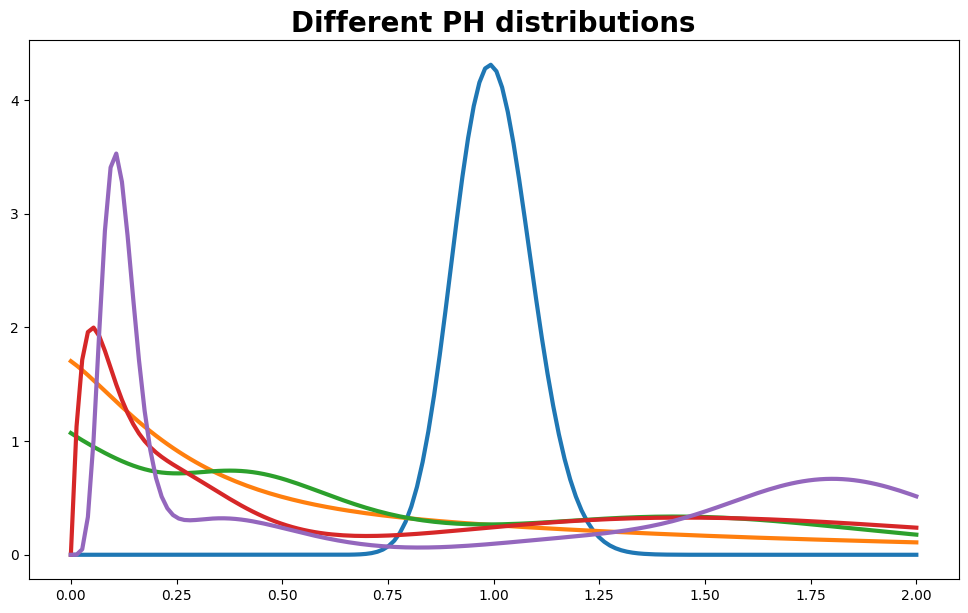

In [30]:
plt.figure(figsize=(12,7))
for ind in range(5):

    a, A ,moms, PH_samples = sample(1, 150)
    x_vals  = np.linspace(0,2,150)
    y_vals = compute_pdf_within_range(x_vals, a, A)
   
    plt.plot(x_vals, y_vals, lw = 3)
    print('The Variance is: '+ str(((moms[1]-moms[0]**2))[0])[:6])
plt.title('Different PH distributions', fontsize= 20, fontweight = 'bold')
plt.show()

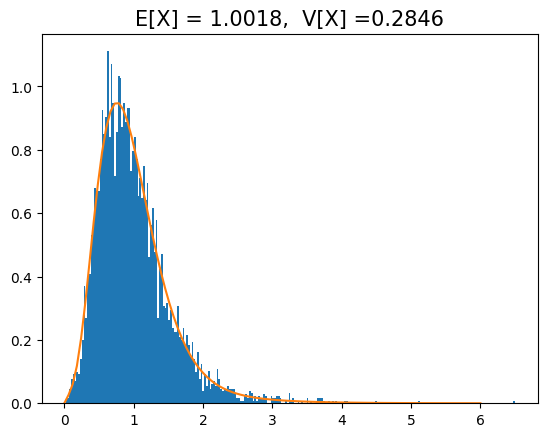

In [31]:
a, S ,moms, PH_samples = sample(5000, 20)
x_vals  = np.linspace(0,6,100)
y_vals = compute_pdf_within_range(x_vals, a, S)


plt.figure()
plt.hist(PH_samples, density = True, bins = 250)
plt.plot(x_vals, y_vals)
plt.title('E[X] = '+str(PH_samples.mean())[:6] + ',  V[X] ='+ str((PH_samples.std())**2)[:6], fontsize= 15)
plt.show()

<div dir="rtl"> 
    
### פונקציית sample גם מגרילה לנו התפלגות PH וגם דוגמת ממנה. יש לה שני ארגומנטים. הראשון מתאר כמה דגימות לעשות והשני מה גודל ההתפלגות.
    
### מה הכוונה גודל ההתפלגות?
    
### התפלגות PH היא התפלגות מיוחדת שמתארת כל מיני קומבינציות של התפלגות מעריכית.
    
### ההתפלגות מתאורת על ידי מטריצה בגודל n על n ווקטור בגודל n
    
### נסמן את הוקטור בa ואת המטריצה ב-S.
    
### הפרמטר moms נותן לנו את עשרת המומנטים הראשונים של ההתפלגות
    
### PH_sample נותן לנו דגימות מההתפלגות
    
### מה זה מומנט של התפלגות??
    
### המומנט ה-i של משתנה מקרי X הוא: $E[X^i]$ 
    
### כלומר התוחלת של המשתנה מקרי בחזקת i
    
## תזכורת:
    
$$ V[X] = E[X^2]-E[X]^2 $$
    
### כלומר השונות היא המומנט השני פחות המומנט הראשון בחזקת 2

### ניתן כמה דוגמאות להתפלגות PH. למעשה זו התפלגות שלפי הצורה שלה יכולה להיות הרבה התפלגויות שונות כמו מעריכית, Erlang ועוד... 
    


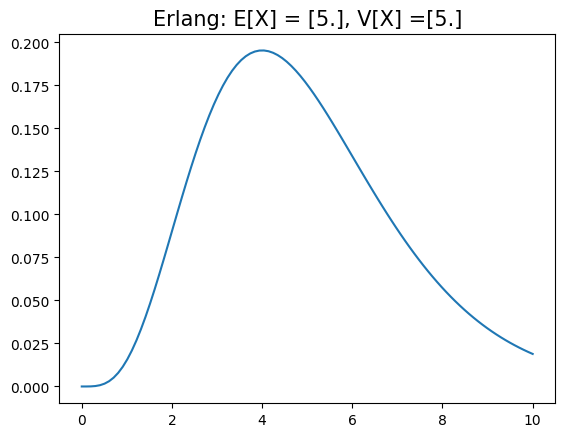

In [32]:
a = np.array([1, 0, 0, 0,0])
S = np.array([[-1,1,0,0,0],[0, -1,1,0,0],[0, 0,-1,1,0],[0, 0,0,-1,1],[0,0,0,0,-1]])
moms_erlang = compute_first_n_moments(a,S, 2)

var_erlang = moms_erlang[1]-moms_erlang[0]**2

x_vals  = np.linspace(0,10,100)
y_vals = compute_pdf_within_range(x_vals, a, S)


plt.figure()
plt.plot(x_vals, y_vals)
plt.title('Erlang: E[X] = ' +str(moms_erlang[0]) + ', V[X] ='+ str(var_erlang)[:5],  fontsize= 15 )
plt.show()

<div dir="rtl">

    
## Hyper-Exponential עירוב של מעריכים
    

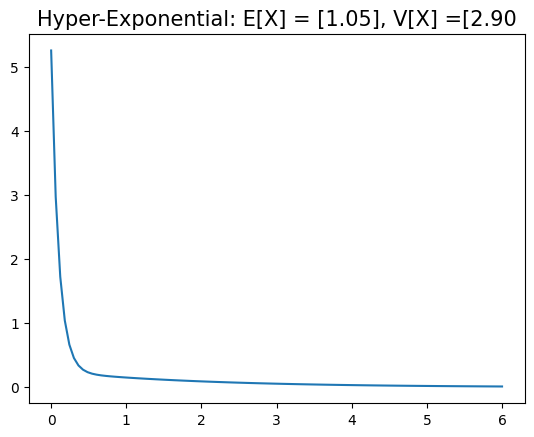

In [33]:
a = np.array([0.5, 0.5])
S = np.array([[-.5,0],[0,-10]])
moms_hyper = compute_first_n_moments(a,S, 2)

var_hyper = (moms_hyper[1]-moms_hyper[0]**2)

x_vals  = np.linspace(0,6,100)
y_vals = compute_pdf_within_range(x_vals, a, S)


plt.figure()
plt.plot(x_vals, y_vals)
plt.title('Hyper-Exponential: E[X] = ' +str(moms_hyper[0]) + ', V[X] ='+ str(var_hyper)[:6],  fontsize= 15 )
plt.show()



<div dir="rtl">

## זה נראה שהתפלגות הhyper יותר רחבה מהתפלגות erlang אבל בדוגמה שלנו למעלה השונות בErlang דווקא יותר גדולה. איך זה יכול להיות?
    
### נשים לב שהתוחלת בדוגמא של הErlang הרבה יותר גדולה. יש לזה חשיבות רבה. כשמדברים על מספרים יותר אז השונות מקבלת משמעות אחרת.
    
### ניקח דוגמה קיצונים. בואו נניח שבנאדם מרוויח הממוצע מיליון שקל. השונות של הרווח הוא 10 שקלים. כלומר הוא מרוויח באיזור של 999,990 ו1000010
    
### במקרה של תוחלת של מיליון, אינטיאוטטיבית 10 שקלים זה מאד נמוך. אבל עדיין מדובר בשונות יותר גדולה מכל הדוגמאות לעיל.
    
## אז מה עושים?
    
### מנרמלים!!!
    
## אבל איך???
    
### SCV: squared coefficient of variation


$$ SCV = \frac{V[X]}{E[X]^2} $$

<div dir="rtl">
    
## בואו נחשב את SCV בשתי הדוגמאות למעלה של הErlang ו-Hyper-Exponential

In [34]:
## Erlang

SCV_erlang = var_erlang/moms_erlang[0]**2

SCV_hyper = var_hyper/moms_hyper[0]**2

SCV_erlang, SCV_hyper


(array([0.2]), array([2.63718821]))

<div dir="rtl">

    
## הSCV של הhyper הרבה יותר גדול!!!
    
### נראה כיצד זה משפיע על התור. ניקח 2 דוגמאות שהתפלגות בין הגעות זהה לחלוטין. אבל ההתפלגות של זמני השירות שונה. התוחלת תהיה אותו דבר אבל פעם אחת עם שונות גדולה (ולכן SCV) גדולה יותר. נראה כיצד זה משפיע על זמני המתנה. 

In [40]:
lamda =  0.7
a = np.array([0.05, 0.95])
S = np.array([[-0.1, 0],[0,-(0.95/0.5)]])
moms_hyper = compute_first_n_moments(a,S, 2)

print('E[X] = ', moms_hyper[0])
print('V[X] = ', moms_hyper[1]- moms_hyper[0]**2)

services = SamplesFromPH(ml.matrix(a), S, 1900000)

queue_single_station = Queue_single_station(lamda, services, 150000)
queue_single_station.run()

steady_hyper = queue_single_station.get_steady_single_station()[:20]

print('Steady state: ', queue_single_station.get_steady_single_station()[:10])

print('Average sojourn time: ',  np.array(queue_single_station.waiting_times).mean())



E[X] =  [1.]
V[X] =  [9.52631579]
Steady state:  [0.30014219 0.12874315 0.06552052 0.04267341 0.03285757 0.02816964
 0.02502299 0.0221417  0.02132478 0.0205063 ]
Average sojourn time:  13.509939530289618


In [41]:
lamda =  0.7

a = np.array([1, 0, 0, 0,0])
S = np.array([[-5,5,0,0,0],[0, -5,5,0,0],[0, 0,-5,5,0],[0, 0,0,-5,5],[0,0,0,0,-5]])

moms_elrang = compute_first_n_moments(a,S, 2)

print('E[X] = ', moms_elrang[0])
print('V[X] = ', moms_elrang[1]- moms_elrang[0]**2)

services = SamplesFromPH(ml.matrix(a), S, 1900000)

queue_single_station = Queue_single_station(lamda, services, 150000)
queue_single_station.run()

queue_single_erlang = queue_single_station.get_steady_single_station()[:20]
steady_erlang = queue_single_station.get_steady_single_station()[:20]


print('Steady state: ', queue_single_station.get_steady_single_station()[:10])

print('Average sojourn time: ',  np.array(queue_single_station.waiting_times).mean())

E[X] =  [1.]
V[X] =  [0.2]
Steady state:  [0.30183844 0.27959992 0.18098973 0.10443021 0.05833508 0.03216554
 0.01837166 0.01028806 0.00610773 0.003352  ]
Average sojourn time:  2.379542942399962


<div dir="rtl">

# לפנינו השוואה בין התפלגות מצב יציב עבור 2 מערכות תורים.
### 1. התפלגות הגעה מעריכית ושירות Hyper-Exponential עם SCV 9.52
### 2. התפלגות הגעה מעריכית עם שירות Eralng עם SCV 0.2

### שתי המערכות עם אותו קצב הגעה ואותה תוחלת שירות. איפה יש תור ארוך יותר?

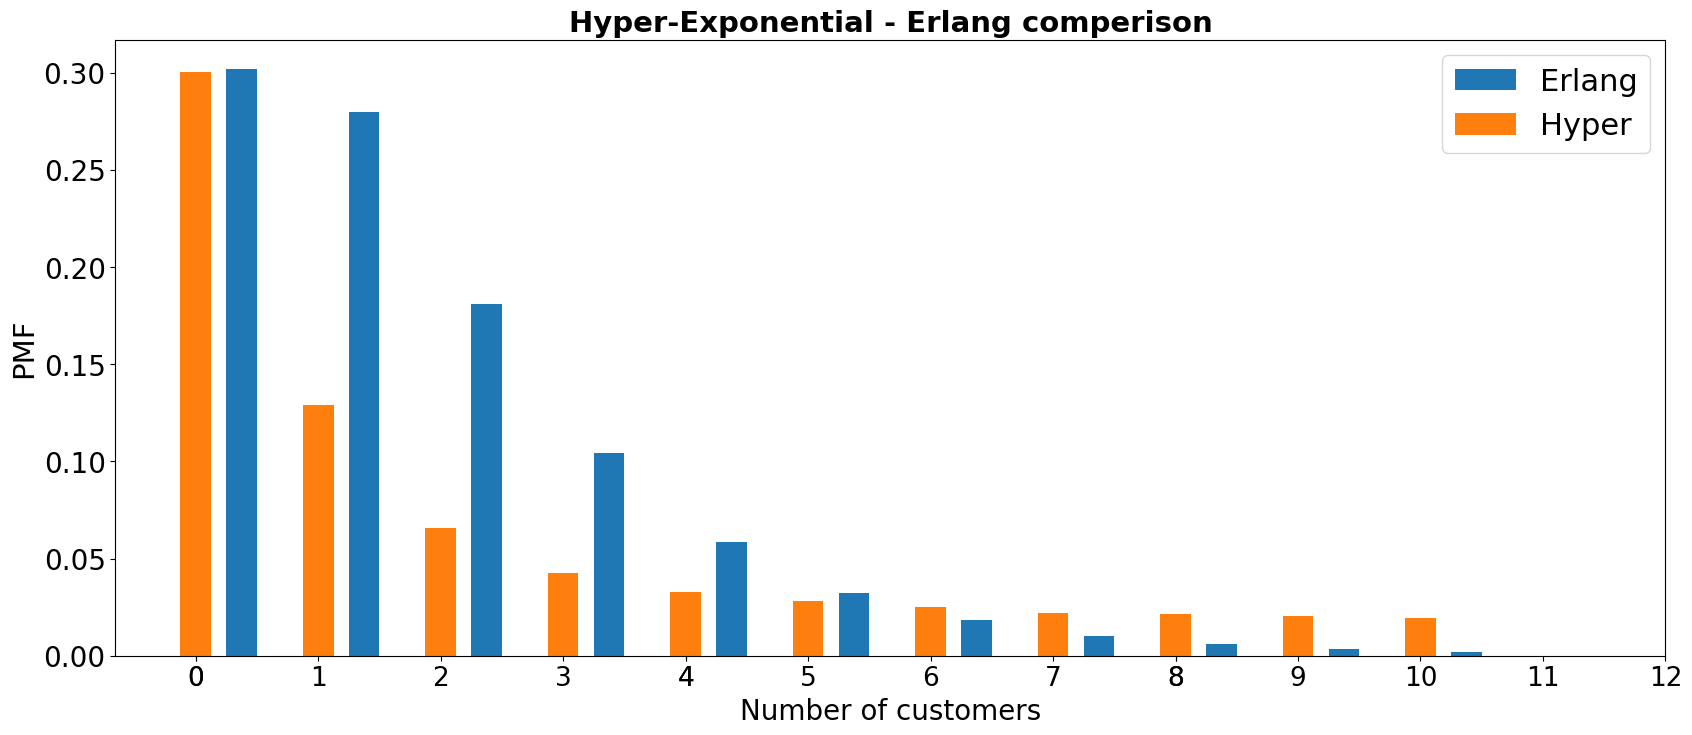

In [42]:
fig, (ax1) = plt.subplots(1, 1, figsize=(20, 8))
width = 0.25
max_probs = 11
rects1 = ax1.bar(1.5*width+np.arange(max_probs), steady_erlang[:11], width, label='Erlang')
rects2 = ax1.bar(np.arange(max_probs) , steady_hyper[:11], width, label='Hyper')
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Hyper-Exponential - Erlang comperison' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

<div dir="rtl">

## נראה שמערכת עם השירות של Hyper-exponential יש הסתברויות גבוהות יותר בערכים הגבוהים ונומוכות יותר בערכים הנמוכים. כלומר - המערכת שם יותר עמוסה.

### נעשה השווה בתוחלת מספר הצרכנים במערכת

In [43]:
(steady_erlang*np.arange(steady_erlang.shape[0])).sum()

np.float64(1.6609040435059301)

In [44]:
(steady_hyper*np.arange(steady_hyper.shape[0])).sum()

np.float64(3.316271120325404)

<div dir="rtl">

## במערכת של Erlang הממוצע הוא 1.66 ואילו במערכת של הHyper הממוצע הוא 3.31